# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:** Abdul Wali
- **Student ID:** 023-24-0174
- **Section:** F
- **GitHub:** AWS9760
- **Kaggle:** https://www.kaggle.com/damonsalvatore9760
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

---
## Part 0 — Setup and the Data

In [1]:
# 1. Install imbalanced-learn once (works in Colab / Jupyter) and import everything
import importlib, subprocess, sys
if importlib.util.find_spec("imblearn") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"], check=True)

import glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
SEED = 42
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = None

In [2]:
# 2. Load and inspect
path = next((p for pat in ["healthcare-dataset-stroke-data.csv", "healthcare-dataset-stroke-data*.csv",
                           "/content/healthcare-dataset-stroke-data*.csv", "/kaggle/input/**/healthcare-dataset-stroke-data.csv"]
             for p in glob.glob(pat, recursive=True)), None)
if path is None:
    raise FileNotFoundError("Upload healthcare-dataset-stroke-data.csv next to this notebook (Colab: Files panel).")
raw = pd.read_csv(path)
print("Loaded:", path, "| shape:", raw.shape)
missing = raw.isna().sum()
print("Columns with missing values:", missing[missing > 0].to_dict())
print("\nGender counts:", raw["gender"].value_counts().to_dict())
stroke_counts = raw["stroke"].value_counts()
display(pd.DataFrame({"count": stroke_counts, "percent": (stroke_counts / len(raw) * 100).round(2)}))

Loaded: healthcare-dataset-stroke-data_1.csv | shape: (5110, 12)
Columns with missing values: {'bmi': 201}

Gender counts: {'Female': 2994, 'Male': 2115, 'Other': 1}


,count,percent
stroke,,
0,4861,95.130
1,249,4.870


In [3]:
# 3. Clean: drop the identifier, drop the 1-row gender category, one-hot encode the text columns
df = raw.drop(columns=["id"])
n_other = int((df["gender"] == "Other").sum())
df = df[df["gender"] != "Other"].reset_index(drop=True)
print(f"Removed 'id' and {n_other} row(s) with gender = 'Other' -> {df.shape}")

y = df["stroke"]
text_cols = df.drop(columns="stroke").select_dtypes(exclude="number").columns.tolist()
X = pd.get_dummies(df.drop(columns="stroke"), columns=text_cols, drop_first=True).astype(float)
print("Encoded text columns:", text_cols)
print("X shape:", X.shape)

Removed 'id' and 1 row(s) with gender = 'Other' -> (5109, 11)
Encoded text columns: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
X shape: (5109, 15)


In [4]:
# 4. Split 80/20 (stratified), impute bmi with the TRAIN median, scaled copy for Logistic Regression
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X_train.copy(), X_test.copy()

bmi_median = X_train["bmi"].median()                       # learned from TRAIN only
print(f"Train median bmi = {bmi_median:.1f} | missing bmi: train {X_train['bmi'].isna().sum()}, test {X_test['bmi'].isna().sum()}")
X_train["bmi"] = X_train["bmi"].fillna(bmi_median)
X_test["bmi"] = X_test["bmi"].fillna(bmi_median)

scaler = StandardScaler().fit(X_train)                    # fitted on TRAIN only
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# 5. Stroke cases per set
n_tr_pos, n_te_pos = int(y_train.sum()), int(y_test.sum())
print(f"Train: {len(y_train)} patients, {n_tr_pos} strokes ({y_train.mean():.2%})")
print(f"Test : {len(y_test)} patients, {n_te_pos} strokes ({y_test.mean():.2%})")

Train median bmi = 28.1 | missing bmi: train 163, test 38
Train: 4087 patients, 199 strokes (4.87%)
Test : 1022 patients, 50 strokes (4.89%)


**Observations:** The file has 5,110 patients and 12 columns. Only `bmi` has missing values (201, about 3.9%). Gender has 2,994 women, 2,115 men and a single "Other" row. One row can never appear in both train and test or teach the model anything, so I removed it. Only 249 patients (4.87%) had a stroke against 4,861 who did not. After the split, the training set has 199 strokes out of 4,087 patients and the test set 50 out of 1,022. The bmi median (28.1) and the scaler were learned from the training rows only.

**Question**

(a) The data is heavily imbalanced: about 1 stroke for every 20 non-stroke patients (4.9%). `stratify=y` keeps that same stroke rate in both sets (4.87% train, 4.89% test); without it, a random split could put noticeably more or fewer strokes in the test set and change every metric. Even so, the test set has only 50 strokes, so one patient more or less caught changes recall by 2 percentage points. Test metrics for the stroke class are therefore noisy and should not be over-interpreted.

---
## Part 1 — The Accuracy Trap

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Majority-class baseline,0.951,0.000,0.000,0.000,0.500,0.049
Logistic Regression (default),0.952,1.000,0.020,0.039,0.839,0.269


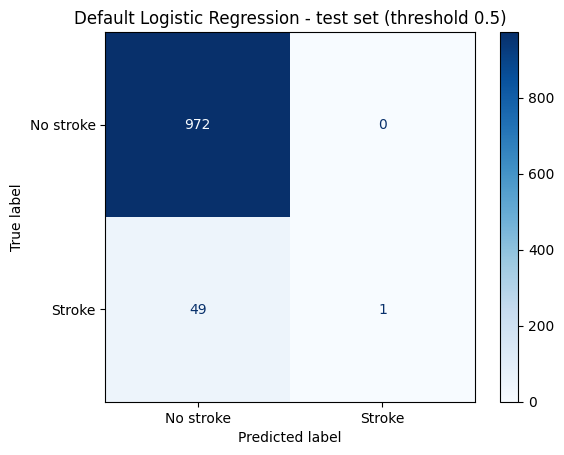

TN=972  FP=0  FN=49  TP=1


In [5]:
# Helper used for the whole lab: fit a model and return the six test metrics
def evaluate(model, X_tr, y_tr, X_te, y_te, threshold=0.5):
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred, zero_division=0),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_te, proba),
            "PR AUC": average_precision_score(y_te, proba)}


baseline = DummyClassifier(strategy="most_frequent")
m_base = evaluate(baseline, X_train, y_train, X_test, y_test)
lr_default = LogisticRegression(max_iter=1000, random_state=SEED)
m_lr = evaluate(lr_default, X_train_s, y_train, X_test_s, y_test)

part1 = pd.DataFrame([m_base, m_lr], index=["Majority-class baseline", "Logistic Regression (default)"])
display(part1)

cm_lr = confusion_matrix(y_test, lr_default.predict(X_test_s))
tn1, fp1, fn1, tp1 = cm_lr.ravel()
ConfusionMatrixDisplay(cm_lr, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues", values_format="d")
plt.title("Default Logistic Regression - test set (threshold 0.5)")
plt.show()
print(f"TN={tn1}  FP={fp1}  FN={fn1}  TP={tp1}")

**Observation:** The baseline never predicts a stroke and still reaches 0.951 accuracy. The default Logistic Regression reaches 0.952, but its confusion matrix shows it flagged only 1 patient and found 1 of the 50 strokes (recall 0.020).

**Questions**

(a) Accuracy is almost the same: 0.951 for the baseline and 0.952 for Logistic Regression, a difference of one patient. A model that does nothing already gets about 95% because 95% of the patients are healthy, so accuracy cannot tell a useful model from a useless one here. The other metrics do separate them: the baseline has ROC AUC 0.5 and PR AUC 0.049 (= the stroke rate), while Logistic Regression has ROC AUC 0.839 and PR AUC 0.269. So the model *has* learned something, but at the 0.5 threshold it is practically never used.

(b) A false negative is a patient who will have a stroke but is told they are not at risk, so they get no follow-up, tests or treatment. That is the most dangerous mistake for a hospital. The default model makes 49 of them out of 50. Instead of accuracy we should look at **recall** (how many strokes we catch), **precision** (how many flagged patients really had a stroke, i.e. the cost of false alarms), F1, and the threshold-free **ROC AUC** and **PR AUC**, which show whether the model can rank risky patients above safe ones at all.

---
## Part 2 — Underfitting, Overfitting, Bias and Variance

### Task 2.1 — Validation curve

,Train AUC,CV AUC,CV AUC std
max_depth,,,
1,0.717,0.732,0.016
2,0.821,0.817,0.027
3,0.838,0.816,0.029
4,0.858,0.818,0.031
5,0.876,0.792,0.034
6,0.903,0.759,0.049
7,0.928,0.738,0.057
8,0.949,0.714,0.043
9,0.968,0.681,0.030


Best depth by CV AUC: 4 (0.818)


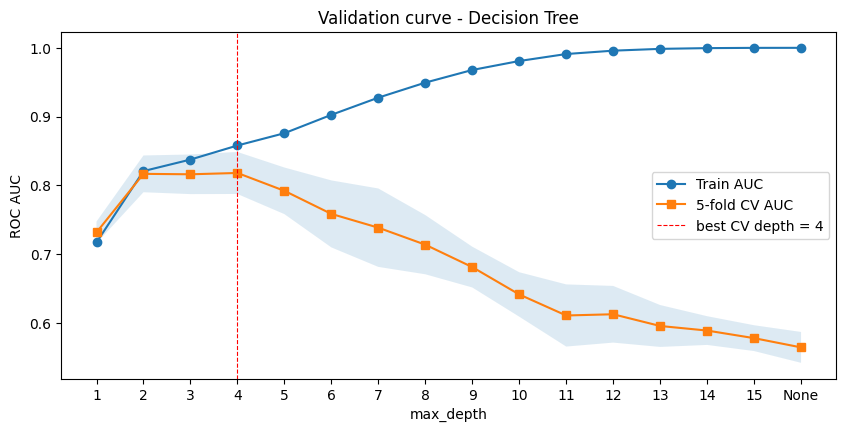

In [6]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    cv_auc = cross_val_score(tree, X_train, y_train, cv=cv5, scoring="roc_auc")
    tree.fit(X_train, y_train)
    rows.append({"max_depth": "None" if d is None else d,
                 "Train AUC": roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]),
                 "CV AUC": cv_auc.mean(), "CV AUC std": cv_auc.std()})
val_curve = pd.DataFrame(rows).set_index("max_depth")
display(val_curve)
best_depth = val_curve["CV AUC"].idxmax()
print("Best depth by CV AUC:", best_depth, f"({val_curve.loc[best_depth, 'CV AUC']:.3f})")

labels_x = [str(d) for d in val_curve.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(labels_x, val_curve["Train AUC"], "o-", label="Train AUC")
ax.plot(labels_x, val_curve["CV AUC"], "s-", label="5-fold CV AUC")
ax.fill_between(labels_x, val_curve["CV AUC"] - val_curve["CV AUC std"], val_curve["CV AUC"] + val_curve["CV AUC std"], alpha=0.15)
ax.axvline(str(best_depth), color="red", linestyle="--", linewidth=0.8, label=f"best CV depth = {best_depth}")
ax.set_xlabel("max_depth"); ax.set_ylabel("ROC AUC"); ax.set_title("Validation curve - Decision Tree")
ax.legend()
plt.show()

**Observation:** Train AUC rises steadily with depth and reaches 1.000 without a limit. CV AUC rises from 0.732 (depth 1) to a peak of 0.818 at depth 4, then falls steadily to 0.564 with no limit. Depths 2, 3 and 4 are tied (0.817, 0.816, 0.818), well within one CV standard deviation (about 0.03).

### Task 2.2 — Learning curves

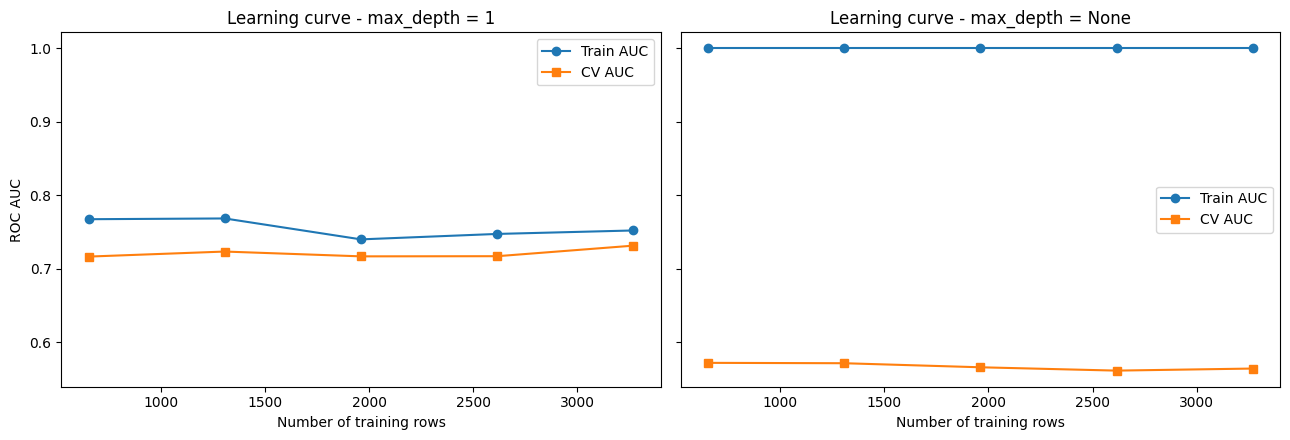

max_depth = 1


,Train AUC,CV AUC
Train rows,,
653,0.768,0.717
1307,0.769,0.724
1961,0.740,0.717
2615,0.748,0.717
3269,0.752,0.732


max_depth = None


,Train AUC,CV AUC
Train rows,,
653,1.000,0.572
1307,1.000,0.572
1961,1.000,0.566
2615,1.000,0.562
3269,1.000,0.564


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
lc = {}
for ax, d in zip(axes, [1, None]):
    sizes, tr_sc, va_sc = learning_curve(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
                                         train_sizes=np.linspace(0.2, 1.0, 5), cv=cv5, scoring="roc_auc")
    lc[d] = pd.DataFrame({"Train rows": sizes, "Train AUC": tr_sc.mean(axis=1), "CV AUC": va_sc.mean(axis=1)})
    ax.plot(sizes, tr_sc.mean(axis=1), "o-", label="Train AUC")
    ax.plot(sizes, va_sc.mean(axis=1), "s-", label="CV AUC")
    ax.set_title(f"Learning curve - max_depth = {d}")
    ax.set_xlabel("Number of training rows")
    ax.legend()
axes[0].set_ylabel("ROC AUC")
plt.tight_layout()
plt.show()
for d in [1, None]:
    print(f"max_depth = {d}")
    display(lc[d].set_index("Train rows"))

**Observation:** For depth 1, train and CV AUC are both low and close together (around 0.72–0.77) at every training size. For depth None, train AUC is always 1.000 while CV AUC stays near 0.57, a gap of more than 0.4, and adding rows (653 → 3,269) does not close it.

### Task 2.3 — Measure variance directly

In [8]:
rng = np.random.default_rng(SEED)
var_rows, avg_probs = [], {}
for d in [1, 3, None]:
    probs = np.zeros((40, len(X_test)))
    for b in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        tree = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = tree.predict_proba(X_test)[:, 1]
    aucs = [roc_auc_score(y_test, p) for p in probs]
    avg_probs[d] = probs.mean(axis=0)
    var_rows.append({"max_depth": "None" if d is None else d,
                     "Mean prediction variance": probs.var(axis=0).mean(),
                     "Mean AUC of 40 single trees": np.mean(aucs), "Std AUC of single trees": np.std(aucs),
                     "AUC of averaged prediction": roc_auc_score(y_test, avg_probs[d])})
variance_table = pd.DataFrame(var_rows).set_index("max_depth")
variance_table["Gain from averaging"] = variance_table["AUC of averaged prediction"] - variance_table["Mean AUC of 40 single trees"]
display(variance_table)
for d, r in variance_table.iterrows():
    print(f"max_depth {d}: mean prediction variance = {r['Mean prediction variance']:.5f}")

,Mean prediction variance,Mean AUC of 40 single trees,Std AUC of single trees,AUC of averaged prediction,Gain from averaging
max_depth,,,,,
1,0.001,0.762,0.016,0.813,0.051
3,0.002,0.796,0.012,0.834,0.038
None,0.042,0.555,0.026,0.757,0.201


max_depth 1: mean prediction variance = 0.00068
max_depth 3: mean prediction variance = 0.00167
max_depth None: mean prediction variance = 0.04197


**Observation (variance table):** The average variance of a patient's predicted probability is 0.0007 for depth 1 and 0.0017 for depth 3, but 0.0420 for the unlimited tree, more than 20 times larger. Averaging the 40 trees improves AUC for every depth, and by far the most for the unlimited tree (+0.201).

**Questions**

(a) **Underfitting:** depth 1. Train AUC 0.717 and CV AUC 0.732 are both low and close together, so the model is too simple even for the training data. **Good zone:** depths 2–4. For example depth 3 has train 0.838 and CV 0.816. **Overfitting:** from depth 5–6 onwards the gap grows; depth 10 has train 0.981 but CV only 0.641, and no limit gives train 1.000 but CV 0.564. Depth 4 has the highest CV AUC, but depths 2–4 differ by less than 0.002, far below the fold standard deviation. I would choose **depth 3**: it scores the same, has a smaller train–CV gap (0.021 against 0.040 for depth 4), and is easier to read.

(b) **High bias** (depth 1): train and CV curves are both low and lie close together. The model cannot even fit the training data well, so more rows do not help (CV stays around 0.72–0.73 from 653 to 3,269 rows); it needs a more flexible model. **High variance** (depth None): train AUC is perfect (1.000) but CV AUC is far lower (about 0.57), so there is a large gap. In theory more data narrows this gap, but here the CV curve is flat, so a few thousand more rows will not fix it. Limiting the depth or averaging many trees will.

(c) Variance grows strongly with depth: 0.0007 → 0.0017 → 0.0420. The unlimited tree's predictions change a lot whenever a few training rows change. Averaging the 40 trees helps every depth, but most where the variance is highest: the unlimited trees go from a mean AUC of 0.555 (single trees) to 0.757 (averaged), while depth 3 goes from 0.796 to 0.834. Averaging cancels out the random, data-dependent errors (variance) but cannot remove a systematic error (bias). This is exactly what **Random Forest** does in Lab 4: it trains many deep trees on bootstrap samples (plus random feature subsets) and averages them, keeping the low bias of deep trees while removing much of their variance.

(d) Every model's error comes from **bias** (being too simple to capture the real pattern) and **variance** (being so flexible that it also learns the noise of the particular training sample). Making a model more complex lowers bias but raises variance, so the best model sits in between. **Depth 1** is high bias / low variance (underfits). **Depth 3** is near the sweet spot (both low enough, best CV AUC). **Depth None** is low bias / very high variance (memorises the training data, train AUC 1.000, CV 0.564).

---
## Part 3 — ROC, AUC, Precision-Recall and Thresholds

### Task 3.1 — Compare models with curves

,ROC AUC,PR AUC (AP)
Model,,
Logistic Regression,0.839,0.269
Decision Tree (depth 3),0.796,0.162
Random Forest,0.822,0.226


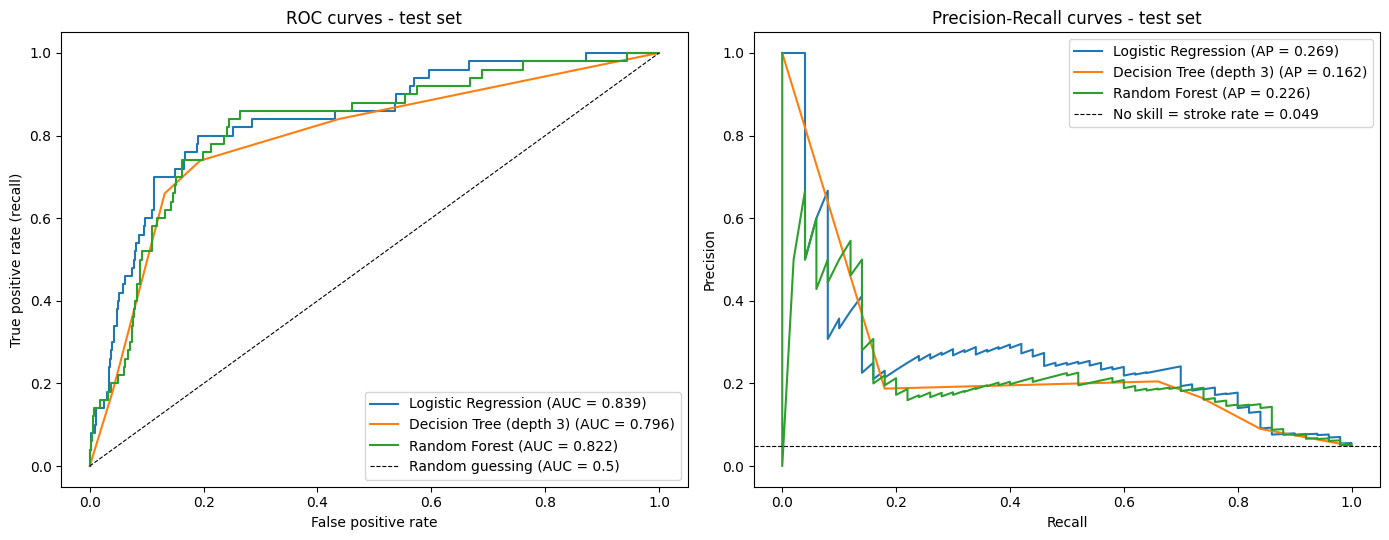

In [9]:
models3 = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=SEED), X_train_s, X_test_s),
    "Decision Tree (depth 3)": (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1), X_train, X_test),
}
proba3, rows = {}, []
for name, (model, Xtr, Xte) in models3.items():
    model.fit(Xtr, y_train)
    proba3[name] = model.predict_proba(Xte)[:, 1]
    rows.append({"Model": name, "ROC AUC": roc_auc_score(y_test, proba3[name]),
                 "PR AUC (AP)": average_precision_score(y_test, proba3[name])})
curves_table = pd.DataFrame(rows).set_index("Model")
display(curves_table)

no_skill = y_test.mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in proba3.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {curves_table.loc[name, 'ROC AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} (AP = {curves_table.loc[name, 'PR AUC (AP)']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random guessing (AUC = 0.5)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)"); axes[0].set_title("ROC curves - test set")
axes[0].legend(loc="lower right")
axes[1].axhline(no_skill, color="k", linestyle="--", linewidth=0.8, label=f"No skill = stroke rate = {no_skill:.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curves - test set")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

**Observation:** On ROC AUC the order is Logistic Regression (0.839), Random Forest (0.822), Decision Tree (0.796). All three ROC curves are far above the diagonal. The PR curves tell a much more modest story: precision starts high only for the few most confident patients and quickly falls below 0.3. Average precision is 0.269 / 0.226 / 0.162, against a no-skill line of 0.049. The depth-3 tree has only a few distinct probability values (one per leaf), so its curves are made of a few long straight segments.

### Task 3.2 — Choose a decision threshold

Chosen threshold (highest with train OOF recall >= 0.80): 0.0509
On the training OOF predictions: recall 0.804, precision 0.136

TEST at threshold 0.0509: recall 0.820, precision 0.135
Patients flagged: 303 of 1022 | true strokes among them: 41 | false alarms: 262 | missed strokes: 9


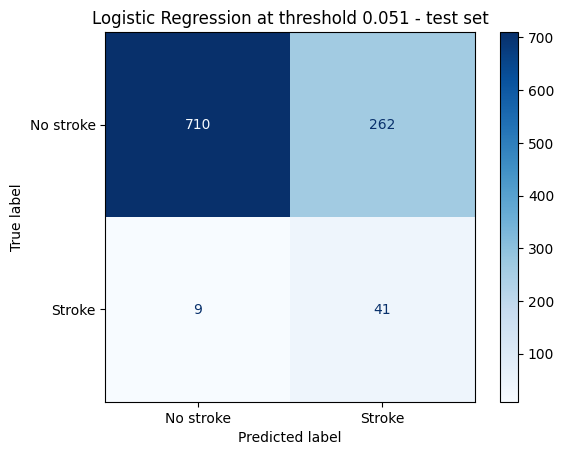

In [10]:
# Out-of-fold probabilities on the TRAINING data only. The scaler sits inside the pipeline,
# so in every fold it is fitted on the four training folds only.
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof = cross_val_predict(lr_pipe, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]

candidates = np.unique(oof)[::-1]                      # from high to low
chosen_thr = next(t for t in candidates if recall_score(y_train, (oof >= t).astype(int)) >= 0.80)
oof_pred = (oof >= chosen_thr).astype(int)
print(f"Chosen threshold (highest with train OOF recall >= 0.80): {chosen_thr:.4f}")
print(f"On the training OOF predictions: recall {recall_score(y_train, oof_pred):.3f}, precision {precision_score(y_train, oof_pred):.3f}")

# Apply to the test probabilities of the Logistic Regression trained on all training rows
p_lr_test = proba3["Logistic Regression"]
pred_thr = (p_lr_test >= chosen_thr).astype(int)
cm_thr = confusion_matrix(y_test, pred_thr)
tn_t, fp_t, fn_t, tp_t = cm_thr.ravel()
thr_rec, thr_prec = recall_score(y_test, pred_thr), precision_score(y_test, pred_thr)
print(f"\nTEST at threshold {chosen_thr:.4f}: recall {thr_rec:.3f}, precision {thr_prec:.3f}")
print(f"Patients flagged: {pred_thr.sum()} of {len(y_test)} | true strokes among them: {tp_t} | false alarms: {fp_t} | missed strokes: {fn_t}")
ConfusionMatrixDisplay(cm_thr, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues", values_format="d")
plt.title(f"Logistic Regression at threshold {chosen_thr:.3f} - test set")
plt.show()

**Observation:** The highest threshold that keeps out-of-fold training recall at or above 0.80 is **0.0509**, almost exactly the stroke rate. It was chosen with training data only (`cross_val_predict` with the scaler inside the pipeline). On the untouched test set it gives recall **0.820** (41 of 50 strokes caught) and precision **0.135**. In total 303 of 1,022 patients are flagged, 262 of them false alarms, and 9 strokes are missed. The training recall (0.804) transferred well to the test set.

**Questions**

(a) ROC AUC measures **ranking**: it is the probability that a randomly chosen stroke patient gets a higher predicted risk than a randomly chosen non-stroke patient, over *all* possible thresholds. Logistic Regression ranks well (AUC 0.839), but because only about 5% of patients have a stroke, its predicted probabilities are small: almost none reach 0.5 (only 1 test patient did). Recall at a fixed threshold of 0.5 is just one point on the ROC curve, near its bottom-left corner. The 0.5 threshold, not the model, is the problem; lowering it to 0.051 moves along the same ROC curve to recall 0.82.

(b) **Precision-Recall** is more informative here. The no-skill level of the PR curve is the stroke rate (0.049), so an AP of 0.269 means the model is about 5.5× better than guessing but still far from good. The curve also shows directly that catching 80% of strokes means a precision of only about 0.13. ROC looks flattering because its false-positive rate divides false alarms by the 972 healthy patients: 262 false alarms are only 27% FPR, even though they outnumber the true strokes found 6.4 to 1. The ROC no-skill diagonal (0.5) does not move with the class balance, so it hides the imbalance.

(c) The price is **262 false alarms**: of 303 flagged patients only 41 (13.5%) really had a stroke, about 6.4 false alarms per stroke caught, and 9 strokes are still missed. *Acceptable:* a missed stroke can mean death or lifelong disability, while a false alarm usually means a cheap follow-up (blood pressure check, glucose test, advice), and flagging about 30% of patients for screening is manageable. *Not acceptable:* if the follow-up is expensive or invasive (scans, medication) or doctors' time is limited, 262 false alarms can overload the clinic, cause anxiety and lead staff to ignore the alerts ("alarm fatigue"). In that case a higher threshold with lower recall would be the better choice.

---
## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare the methods

In [11]:
def make_lr(cw=None):
    return LogisticRegression(max_iter=1000, class_weight=cw, random_state=SEED)

def make_rf(cw=None):
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=cw, random_state=SEED, n_jobs=-1)

samplers = {"none": None, "class_weight='balanced'": None,
            "RandomUnderSampler": RandomUnderSampler(random_state=SEED),
            "RandomOverSampler": RandomOverSampler(random_state=SEED),
            "SMOTE": SMOTE(random_state=SEED)}
rows = []
for model_name, maker, Xtr, Xte in [("Logistic Regression", make_lr, X_train_s, X_test_s),
                                     ("Random Forest", make_rf, X_train, X_test)]:
    for method, sampler in samplers.items():
        if sampler is None:
            X_fit, y_fit = Xtr, y_train                                  # train set unchanged
        else:
            X_fit, y_fit = sampler.fit_resample(Xtr, y_train)          # TRAIN only - test never touched
        cw = "balanced" if method.startswith("class_weight") else None
        m = evaluate(maker(cw), X_fit, y_fit, Xte, y_test)
        rows.append({"Model": model_name, "Method": method, "Train rows": len(y_fit), "Train strokes": int(y_fit.sum()),
                     **{k: m[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}})
resampling = pd.DataFrame(rows).set_index(["Model", "Method"])
display(resampling)

Train rows  Train strokes  \
Model               Method                                               
Logistic Regression none                           4087            199   
                    class_weight='balanced'        4087            199   
                    RandomUnderSampler              398            199   
                    RandomOverSampler              7776           3888   
                    SMOTE                          7776           3888   
Random Forest       none                           4087            199   
                    class_weight='balanced'        4087            199   
                    RandomUnderSampler              398            199   
                    RandomOverSampler              7776           3888   
                    SMOTE                          7776           3888   

                                             Precision  Recall    F1  ROC AUC  \
Model               Method                                                      
Logistic Regression none                         1.000   0.020 0.039    0.839   
                    class_weight='balanced'      0.135   0.800 0.231    0.840   
                    RandomUnderSampler           0.125   0.820 0.216    0.835   
                    RandomOverSampler            0.133   0.800 0.229    0.838   
                    SMOTE                        0.134   0.800 0.229    0.841   
Random Forest       none                         0.000   0.000 0.000    0.822   
                    class_weight='balanced'      0.214   0.300 0.250    0.811   
                    RandomUnderSampler           0.105   0.840 0.187    0.820   
                    RandomOverSampler            0.188   0.320 0.237    0.811   
                    SMOTE                        0.500   0.060 0.107    0.798   

                                             PR AUC  
Model               Method                           
Logistic Regression none                      0.269  
                    class_weight='balanced'   0.260  
                    RandomUnderSampler        0.234  
                    RandomOverSampler         0.265  
                    SMOTE                     0.288  
Random Forest       none                      0.226  
                    class_weight='balanced'   0.209  
                    RandomUnderSampler        0.203  
                    RandomOverSampler         0.191  
                    SMOTE                     0.229

**Observation:** For Logistic Regression, every rebalancing method lifts recall from 0.02 to about 0.80, drops precision to about 0.13, and leaves ROC AUC unchanged (0.835–0.841). Random Forest reacts very differently from method to method: recall ranges from 0.06 (SMOTE) to 0.84 (undersampling). Undersampling keeps only 398 of the 4,087 training rows, while oversampling and SMOTE grow the set to 7,776 rows with 3,888 "strokes", of which only 199 are real patients.

### Task 4.2 — The classic mistake

In [12]:
# WRONG ORDER (for demonstration only): impute + SMOTE on ALL rows, THEN split
X_all = X.copy()
X_all["bmi"] = X_all["bmi"].fillna(X_all["bmi"].median())
X_sm_all, y_sm_all = SMOTE(random_state=SEED).fit_resample(X_all, y)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_sm_all, y_sm_all, test_size=0.2, stratify=y_sm_all, random_state=SEED)
m_wrong = evaluate(make_rf(), Xw_tr, yw_tr, Xw_te, yw_te)

n_synth_test = int(((Xw_te.index >= len(X_all)) & (yw_te == 1)).sum())
print(f"Wrong-order test set: {len(yw_te)} rows, {int(yw_te.sum())} 'strokes', of which {n_synth_test} are synthetic SMOTE rows "
      f"({n_synth_test / yw_te.sum():.0%})")

correct = resampling.loc[("Random Forest", "SMOTE")]
leak_table = pd.DataFrame([{k: m_wrong[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]},
                           correct[["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]].to_dict()],
                          index=["WRONG: SMOTE on all data, then split", "CORRECT: split, then SMOTE on train only"])
display(leak_table)

Wrong-order test set: 1944 rows, 972 'strokes', of which 931 are synthetic SMOTE rows (96%)


,Precision,Recall,F1,ROC AUC,PR AUC
"WRONG: SMOTE on all data, then split",0.996,0.948,0.971,0.995,0.996
"CORRECT: split, then SMOTE on train only",0.500,0.060,0.107,0.798,0.229


**Observation (leakage):** The wrong-order Random Forest looks almost perfect: ROC AUC 0.995, recall 0.948, precision 0.996. The correct pipeline with the same model and SMOTE has ROC AUC 0.798 and recall 0.060. 96% of the "strokes" in the wrong-order test set are synthetic.

**Questions**

(a) **Changed:** the threshold-based numbers. Recall jumped from 0.020 to between 0.800 and 0.820, and precision fell from 1.000 (1 lucky patient) to 0.125–0.135. **Not changed:** ROC AUC stayed at 0.835–0.841, and PR AUC moved only within noise (0.234–0.288). For a linear model, rebalancing mainly changes the **intercept** (the model now believes strokes are about 50% common instead of 5%), so every patient's probability is pushed up while their **order** barely changes. That has the same effect as lowering the 0.5 threshold, and indeed `class_weight='balanced'` (precision 0.135, recall 0.800) gives almost the same result as the threshold of Task 3.2 (0.135 / 0.820). Rebalancing moves the operating point; it does not give the model new knowledge.

(b) No. For Logistic Regression all methods behaved alike, but Random Forest depended strongly on the method. Undersampling reached recall 0.84 and class weights 0.72, but random oversampling reached only 0.32 and SMOTE only 0.06, even though those training sets were 50% "stroke". A likely reason: trees are flexible enough to **isolate** the copied or synthetic stroke rows in their own small leaves (copies sit exactly on top of each other, and SMOTE points lie on short lines between real strokes). The forest learns "stroke" only in those tiny regions, real test patients rarely fall into them, and so the predicted probabilities for new strokes stay below 0.5. Logistic Regression cannot draw tiny regions; it can only shift and tilt one line, so every method has the same effect on it. RF's ROC AUC also dropped slightly with oversampling and SMOTE (0.822 → 0.798).

(c) In the wrong order, SMOTE creates each synthetic stroke by interpolating between real strokes, *before* the split. After the split, most test "strokes" (931 of 972) are synthetic points built from neighbours that ended up in the **training** set, and some of the training "strokes" were built from test patients. The test set is no longer independent: information leaks from the training data into the test set and back. The model is tested on near-copies of what it trained on, and the synthetic points are also much easier to separate than real patients. Recall 0.948 and AUC 0.995 describe how well the model recognises SMOTE's own interpolations, not how well it would screen real patients, for whom the honest result is AUC 0.798. The scaler and imputer were also learned from all rows in that pipeline, which leaks as well.

(d) For this hospital I would pick **`class_weight='balanced'`** (for Logistic Regression), or, equivalently, threshold tuning. It gives the same recall/precision trade-off as the resamplers (0.80 / 0.135) with one parameter, no extra library and no invented patients. Undersampling throws away 3,689 real patients (90% of the data). Random oversampling and SMOTE double the training set and add copied or synthetic patients that no doctor ever saw. SMOTE's small PR AUC gain for LR (0.288 vs 0.269) is within the noise of a 50-stroke test set, and for Random Forest SMOTE was clearly the worst choice.

---
## Part 5 — Noisy Data

### Task 5.1 — Label noise

,Logistic Regression,Decision Tree (depth 3),Decision Tree (no limit),Random Forest
Label noise,,,,
0.000,0.839,0.796,0.580,0.822
0.050,0.824,0.793,0.530,0.800
0.100,0.823,0.795,0.548,0.778
0.200,0.792,0.730,0.549,0.715


At 10% noise, 409 labels are flipped - about 389 healthy patients become 'stroke' while only about 20 of the 199 real strokes are lost.


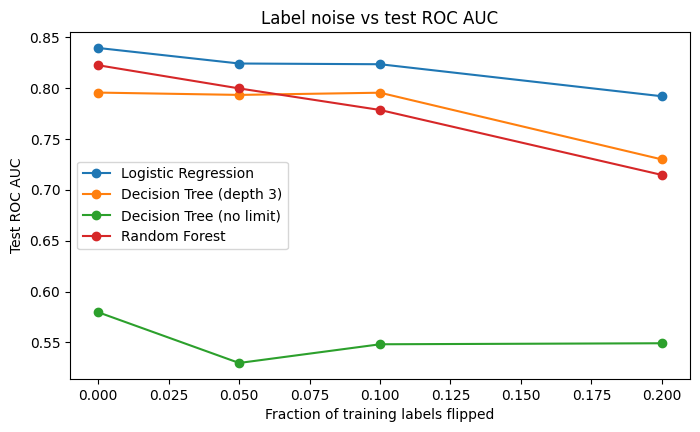

In [13]:
def noise_models():
    return {"Logistic Regression": make_pipeline(StandardScaler(), make_lr()),   # scaler re-fitted on the (noisy) train data
            "Decision Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
            "Decision Tree (no limit)": DecisionTreeClassifier(max_depth=None, random_state=SEED),
            "Random Forest": make_rf()}


def flip_labels(y_in, fraction, rng):
    y_noisy = y_in.copy()
    n = int(round(fraction * len(y_in)))
    idx = rng.choice(len(y_in), n, replace=False)
    y_noisy.iloc[idx] = 1 - y_noisy.iloc[idx]
    return y_noisy


rng = np.random.default_rng(SEED)
label_rows = []
for frac in [0, 0.05, 0.10, 0.20]:
    repeats = 1 if frac == 0 else 5
    scores = {name: [] for name in noise_models()}
    for r in range(repeats):
        y_noisy = flip_labels(y_train, frac, rng)
        for name, model in noise_models().items():
            scores[name].append(roc_auc_score(y_test, model.fit(X_train, y_noisy).predict_proba(X_test)[:, 1]))
    label_rows.append({"Label noise": frac, **{k: np.mean(v) for k, v in scores.items()}})
label_noise = pd.DataFrame(label_rows).set_index("Label noise")
display(label_noise)
n_flipped_10 = int(round(0.10 * len(y_train)))
print(f"At 10% noise, {n_flipped_10} labels are flipped - about {int(round(0.10 * (len(y_train) - n_tr_pos)))} healthy patients "
      f"become 'stroke' while only about {int(round(0.10 * n_tr_pos))} of the {n_tr_pos} real strokes are lost.")

ax = label_noise.plot(marker="o", figsize=(8, 4.5))
ax.set_xlabel("Fraction of training labels flipped"); ax.set_ylabel("Test ROC AUC"); ax.set_title("Label noise vs test ROC AUC")
plt.show()

**Observation:** Logistic Regression loses only 0.047 AUC even at 20% flipped labels, while Random Forest loses 0.108 and the depth-3 tree 0.066 (most of it between 10% and 20%). The unlimited tree is already close to useless without noise (0.580) and stays around 0.53–0.55. Random flipping hits mostly healthy patients because they are 95% of the data: at 10%, about 389 healthy patients become "stroke" while about 20 real strokes become "healthy", so roughly two thirds of the training "strokes" are fake.

### Task 5.2 — Feature noise

,Logistic Regression,Decision Tree (depth 3),Decision Tree (no limit),Random Forest
Feature noise level,,,,
0.000,0.839,0.796,0.580,0.822
0.500,0.832,0.791,0.549,0.805
1.000,0.806,0.749,0.512,0.773
2.000,0.768,0.690,0.499,0.730


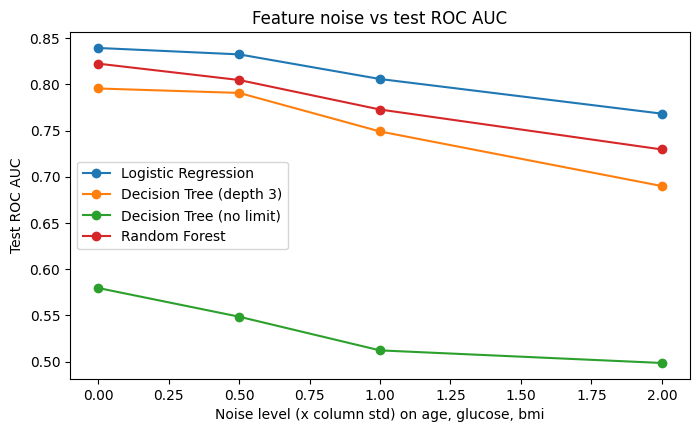

In [14]:
noisy_cols = ["age", "avg_glucose_level", "bmi"]
col_std = X_train[noisy_cols].std()
rng = np.random.default_rng(SEED)
feat_rows = []
for level in [0, 0.5, 1, 2]:
    repeats = 1 if level == 0 else 5
    scores = {name: [] for name in noise_models()}
    for r in range(repeats):
        X_noisy = X_train.copy()
        X_noisy[noisy_cols] = X_noisy[noisy_cols] + rng.normal(size=(len(X_noisy), 3)) * col_std.values * level
        for name, model in noise_models().items():
            scores[name].append(roc_auc_score(y_test, model.fit(X_noisy, y_train).predict_proba(X_test)[:, 1]))
    feat_rows.append({"Feature noise level": level, **{k: np.mean(v) for k, v in scores.items()}})
feature_noise = pd.DataFrame(feat_rows).set_index("Feature noise level")
display(feature_noise)

ax = feature_noise.plot(marker="o", figsize=(8, 4.5))
ax.set_xlabel("Noise level (x column std) on age, glucose, bmi"); ax.set_ylabel("Test ROC AUC")
ax.set_title("Feature noise vs test ROC AUC")
plt.show()

**Observation:** Feature noise lowers every model steadily. At level 2, Logistic Regression drops to 0.768 (−0.071), Random Forest to 0.730 (−0.093), the depth-3 tree to 0.690 (−0.106), and the unlimited tree reaches pure chance (0.499). The scaler in the Logistic Regression pipeline is fitted on the noisy training data, as the manual asks.

### Task 5.3 — SMOTE and noisy labels

In [15]:
rng = np.random.default_rng(SEED)
sm_rows = []
for draw in range(3):
    y_noisy = flip_labels(y_train, 0.10, rng)
    for model_name, maker, Xtr, Xte in [("Logistic Regression", make_lr, X_train_s, X_test_s),
                                         ("Random Forest", make_rf, X_train, X_test)]:
        for use_smote in [False, True]:
            X_fit, y_fit = SMOTE(random_state=SEED).fit_resample(Xtr, y_noisy) if use_smote else (Xtr, y_noisy)
            m = evaluate(maker(), X_fit, y_fit, Xte, y_test)
            sm_rows.append({"Model": model_name, "SMOTE": "with SMOTE" if use_smote else "no SMOTE",
                            "ROC AUC": m["ROC AUC"], "PR AUC": m["PR AUC"], "Recall": m["Recall"], "Precision": m["Precision"],
                            "Train 'strokes'": int(y_fit.sum())})
smote_noise = pd.DataFrame(sm_rows).groupby(["Model", "SMOTE"]).mean()
display(smote_noise)

# reference: the same models with clean labels (from Task 4.1)
display(resampling.loc[[("Logistic Regression", "none"), ("Logistic Regression", "SMOTE"),
                        ("Random Forest", "none"), ("Random Forest", "SMOTE")], ["ROC AUC", "PR AUC", "Recall", "Precision"]])

ROC AUC  PR AUC  Recall  Precision  \
Model               SMOTE                                            
Logistic Regression no SMOTE      0.811   0.232   0.000      0.000   
                    with SMOTE    0.805   0.227   0.793      0.100   
Random Forest       no SMOTE      0.743   0.183   0.000      0.000   
                    with SMOTE    0.679   0.121   0.047      0.278   

                                Train 'strokes'  
Model               SMOTE                        
Logistic Regression no SMOTE            572.000  
                    with SMOTE        3,515.000  
Random Forest       no SMOTE            572.000  
                    with SMOTE        3,515.000

ROC AUC  PR AUC  Recall  Precision
Model               Method                                    
Logistic Regression none      0.839   0.269   0.020      1.000
                    SMOTE     0.841   0.288   0.800      0.134
Random Forest       none      0.822   0.226   0.000      0.000
                    SMOTE     0.798   0.229   0.060      0.500

**Observation (SMOTE + noisy labels):** With 10% flipped labels the training set has about 572 "strokes" (only about 180 real). Without SMOTE neither model flags anyone at 0.5 (recall 0). With SMOTE, Logistic Regression keeps its ranking (ROC AUC 0.811 → 0.805) and gains recall, but Random Forest gets clearly worse (ROC AUC 0.743 → 0.679, PR AUC 0.183 → 0.121).

**Questions**

(a) **Most stable: Logistic Regression.** At 20% label noise its AUC is still 0.792 (−0.047), and at feature-noise level 2 it is 0.768, the best of all four models in both cases. **Most damaged:** the unlimited Decision Tree ends at 0.549 and 0.499, i.e. at or near random guessing. Among the useful models, Random Forest loses the most under label noise (0.822 → 0.715) and the depth-3 tree the most under feature noise (0.796 → 0.690). This follows Part 2: high-variance, flexible models fit whatever is in the training data, wrong labels and noisy values included, while the high-bias linear model cannot follow individual noisy points. It only learns one overall direction, which random noise barely moves.

(b) At comparable levels, **feature noise hurt slightly more**. At 10% label noise, Logistic Regression lost only 0.016 AUC, but at feature noise of 1 std it lost 0.034. At the highest levels, feature noise was worse for Logistic Regression and both trees, while label noise was worse only for Random Forest. Reason: feature noise blurs **age** and **glucose**, the strongest stroke predictors, for *every* patient, including the real strokes. Random label flips land in random places and mainly add a uniform "background" of fake strokes; this shifts all predicted probabilities up but keeps the ranking (and AUC) largely intact for a smooth model.

(c) For Logistic Regression, SMOTE changed little on the ranking metrics (ROC AUC −0.005, PR AUC −0.005); it again acted like a threshold shift (recall 0.79, precision 0.10). For Random Forest it was clearly harmful: ROC AUC fell by 0.064 and PR AUC by 0.061. SMOTE trusts every minority label and creates new points between minority neighbours. When about two thirds of the "strokes" are mislabeled healthy patients, most synthetic strokes are interpolations between healthy patients: SMOTE copies and spreads each wrong label into thousands of new points (3,515 "strokes" after SMOTE). A flexible model like Random Forest then learns many fake "stroke regions" among healthy patients, so SMOTE **amplifies** the label noise instead of averaging it out.

---
## Part 6 — Final Decision and Conclusion

In [16]:
# Final approach: Logistic Regression (scaled, no resampling) with the threshold chosen on training OOF predictions (Task 3.2)
def row(pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Precision": precision_score(y_test, pred, zero_division=0), "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred, zero_division=0), "Patients flagged": int(pred.sum()),
            "False alarms": int(fp), "Missed strokes": int(fn)}

final_table = pd.DataFrame([row((p_lr_test >= 0.5).astype(int)), row(pred_thr)],
                           index=["Logistic Regression, threshold 0.5", f"Logistic Regression, threshold {chosen_thr:.3f} (chosen)"])
display(final_table)
final_auc = roc_auc_score(y_test, p_lr_test)
print(f"Test ROC AUC {final_auc:.3f} | PR AUC {average_precision_score(y_test, p_lr_test):.3f} (the threshold does not change these)")

# how uncertain is the test recall with only this many strokes? (bootstrap of the test set)
rng = np.random.default_rng(SEED)
yt, pt = y_test.values, pred_thr
boot_rec = []
for _ in range(2000):
    i = rng.choice(len(yt), len(yt), replace=True)
    if yt[i].sum() > 0:
        boot_rec.append(recall_score(yt[i], pt[i]))
rec_lo, rec_hi = np.percentile(boot_rec, [2.5, 97.5])
print(f"95% bootstrap interval for the test recall at the chosen threshold: {rec_lo:.2f} - {rec_hi:.2f}")

,Precision,Recall,F1,Patients flagged,False alarms,Missed strokes
"Logistic Regression, threshold 0.5",1.000,0.020,0.039,1,0,49
"Logistic Regression, threshold 0.051 (chosen)",0.135,0.820,0.232,303,262,9


Test ROC AUC 0.839 | PR AUC 0.269 (the threshold does not change these)
95% bootstrap interval for the test recall at the chosen threshold: 0.71 - 0.92


**Observation:** At the default threshold the model flags 1 patient and misses 49 of 50 strokes. At the chosen threshold it flags 303, catches 41 strokes and misses 9, at the cost of 262 false alarms. F1 rises from 0.039 to 0.232. The bootstrap interval shows how uncertain a recall measured on only 50 strokes is: 0.71–0.92.

**Executive Summary**

1. For stroke screening I chose **Logistic Regression on scaled features, without resampling, with a decision threshold of 0.051** instead of 0.5. It had the best ROC AUC (0.839) and PR AUC of the models compared, and was the most robust to noisy data.
2. On the test set it catches **82% of strokes** (41 of 50) with a **precision of 13.5%**; the default threshold caught only 1.
3. The price is 262 false alarms out of 303 flagged patients (about 6.4 per stroke found) and 9 strokes still missed. That is acceptable for a cheap first screening step, not for an expensive treatment.
4. Leakage was avoided: the imputer median, the scaler and every resampler were fitted on the training rows only, and the threshold was chosen from out-of-fold training predictions, never from the test set.
5. The leakage demo showed what happens otherwise: SMOTE before the split inflated the ROC AUC from 0.798 to 0.995.
6. Rebalancing (class weights, under/oversampling, SMOTE) gave Logistic Regression the same trade-off as moving the threshold, so I kept the simplest option.
7. Limitation: the test set has only 50 stroke patients, so each missed stroke changes recall by 2 points (95% bootstrap interval 0.71–0.92). The 80% recall target, and therefore the threshold, is a policy choice that should be set with doctors based on the real cost of a missed stroke versus a false alarm.

**Final Reflection**

(a) How robust Logistic Regression was to wrong labels: flipping 10% of the training labels made about two thirds of the training "strokes" fake, yet its test AUC fell only from 0.839 to 0.823. A close second was how convincing the leaked SMOTE result looked (AUC 0.995): without knowing the correct order, it would be easy to believe.

(b) I would choose the threshold by expected cost (a cost for a missed stroke and a cost for a false alarm) instead of a fixed 80% recall. I would also measure every final metric with repeated stratified cross-validation instead of one test set with 50 strokes, and try interaction or non-linear features (age × hypertension, glucose bands) or a gradient-boosting model with class weights, to see whether the PR AUC of about 0.27 can be improved.